# Data-Driven Digital Twin of a DJI Tello Drone using Controlled Neural ODEs

## Introduction

This project develops a data-driven digital twin of a DJI Tello drone using real flight telemetry collected through ROS 2. The objective is to learn a continuous-time dynamics model capable of predicting the future behavior of the drone from its current state and control inputs.

Instead of manually deriving aerodynamic and rigid-body equations, the drone dynamics are learned directly from real-world telemetry using a Neural Ordinary Differential Equation (Neural ODE).

The project evolved from an initial Gazebo simulation prototype toward a real telemetry-based digital twin using ROS 2 and DJI Tello flight data.

# I- Part 1: Gazebo Simulation.

 Initially we started with a Gazebo-based simulation prototype to explore Neural ODE trajectory learning for drone motion.

Early experiments used manually generated trajectories such as:

- square motion
- circular motion
- Point-to-point.


This section represents the initial simulation prototype of the project. The goal was to test the idea of learning drone trajectories before moving to real Tello data. The code loads simulated point, square, and circle trajectory datasets, tags each trajectory by scenario, and evaluates a simple first-order commanded-motion baseline.

This part is useful as an early proof of concept, but the simulation trajectories are simplified and can contain discontinuous jumps between waypoints. Because of this, the final digital twin is later trained using real Tello telemetry collected through ROS 2.

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


In [ ]:
!pip install torchdiffeq pandas numpy matplotlib scikit-learn -q

In [ ]:
from google.colab import files
uploaded = files.upload()

In [ ]:
def load_and_tag(files, scenario_name):
    dfs = []
    for f in files:
        df = pd.read_csv(f)
        df = df.sort_values("t").reset_index(drop=True)
        df["run_file"] = f
        df["scenario_group"] = scenario_name
        dfs.append(df)
    return pd.concat(dfs, ignore_index=True)

In [ ]:
point_files = [
    "point_to_point.csv",
    "point_to_point_run1.csv",
    "point_to_point_run2.csv",
    "point_to_point_run3.csv",
]

square_files = [
    "square_run1.csv",
    "square_run2.csv",
    "square_run3.csv",
]

circle_files = [
    "circle_run1.csv",
    "circle_run2.csv",
    "circle_run3.csv",
    "circle_run4.csv"
]

In [ ]:
point_df = load_and_tag(point_files, "point")
square_df = load_and_tag(square_files, "square")
circle_df = load_and_tag(circle_files, "circle")

train_df = pd.concat([point_df, square_df], ignore_index=True)
test_df = circle_df.copy()

print("train:", train_df.shape)
print("test :", test_df.shape)
train_df.head()

train: (1130, 13)
test : (583, 13)


,t,scenario,x,y,z,vx,vy,vz,cmd_x,cmd_y,cmd_z,run_file,scenario_group
0,0.100,point_to_point,0.0,0.0,0.091301,0.0,0.0,0.00000,0.0,0.0,0.091301,point_to_point.csv,point
1,0.488,point_to_point,0.0,0.0,0.231433,0.0,0.0,0.36125,0.0,0.0,0.231433,point_to_point.csv,point
2,0.866,point_to_point,0.0,0.0,0.367815,0.0,0.0,0.36125,0.0,0.0,0.367815,point_to_point.csv,point
3,1.261,point_to_point,0.0,0.0,0.510623,0.0,0.0,0.36125,0.0,0.0,0.510623,point_to_point.csv,point
4,1.802,point_to_point,0.0,0.0,0.705794,0.0,0.0,0.36125,0.0,0.0,0.705794,point_to_point.csv,point


In [ ]:
def rmse(a, b):
    return np.sqrt(np.mean((a - b) ** 2))

def add_command_velocities(df):
    outputs = []

    for run_name, run_df in df.groupby("run_file"):
        run_df = run_df.sort_values("t").reset_index(drop=True).copy()

        t = run_df["t"].to_numpy(float)
        cx = run_df["cmd_x"].to_numpy(float)
        cy = run_df["cmd_y"].to_numpy(float)
        cz = run_df["cmd_z"].to_numpy(float)

        ux = np.zeros_like(cx)
        uy = np.zeros_like(cy)
        uz = np.zeros_like(cz)

        if len(t) > 1:
            dt = np.diff(t)
            dt[dt <= 0] = 1e-6

            ux[1:] = np.diff(cx) / dt
            uy[1:] = np.diff(cy) / dt
            uz[1:] = np.diff(cz) / dt

            ux[0] = ux[1]
            uy[0] = uy[1]
            uz[0] = uz[1]

        run_df["u_cmd_x"] = ux
        run_df["u_cmd_y"] = uy
        run_df["u_cmd_z"] = uz
        outputs.append(run_df)

    return pd.concat(outputs, ignore_index=True)

train_df = add_command_velocities(train_df)
test_df = add_command_velocities(test_df)

In [ ]:
def simulate_first_order_commanded(df):
    outputs = []

    for run_name, run_df in df.groupby("run_file"):
        run_df = run_df.sort_values("t").reset_index(drop=True).copy()

        t = run_df["t"].to_numpy(float)
        x = run_df["x"].to_numpy(float)
        y = run_df["y"].to_numpy(float)
        z = run_df["z"].to_numpy(float)

        ux = run_df["u_cmd_x"].to_numpy(float)
        uy = run_df["u_cmd_y"].to_numpy(float)
        uz = run_df["u_cmd_z"].to_numpy(float)

        x_sim = np.zeros_like(x)
        y_sim = np.zeros_like(y)
        z_sim = np.zeros_like(z)

        x_sim[0] = x[0]
        y_sim[0] = y[0]
        z_sim[0] = z[0]

        for k in range(len(t) - 1):
            dt = t[k + 1] - t[k]
            if dt <= 0:
                dt = 1e-6

            x_sim[k + 1] = x_sim[k] + dt * ux[k]
            y_sim[k + 1] = y_sim[k] + dt * uy[k]
            z_sim[k + 1] = z_sim[k] + dt * uz[k]

        run_df["x_sim"] = x_sim
        run_df["y_sim"] = y_sim
        run_df["z_sim"] = z_sim
        outputs.append(run_df)

    return pd.concat(outputs, ignore_index=True)

train_sim = simulate_first_order_commanded(train_df)
test_sim = simulate_first_order_commanded(test_df)

In [ ]:
print("TRAIN RMSE x =", rmse(train_sim["x"], train_sim["x_sim"]))
print("TRAIN RMSE y =", rmse(train_sim["y"], train_sim["y_sim"]))
print("TRAIN RMSE z =", rmse(train_sim["z"], train_sim["z_sim"]))

print("TEST RMSE x =", rmse(test_sim["x"], test_sim["x_sim"]))
print("TEST RMSE y =", rmse(test_sim["y"], test_sim["y_sim"]))
print("TEST RMSE z =", rmse(test_sim["z"], test_sim["z_sim"]))

TRAIN RMSE x = 0.27160019908153094
TRAIN RMSE y = 0.15290233336278045
TRAIN RMSE z = 0.11996910568415532
TEST RMSE x = 0.5084434543380338
TEST RMSE y = 0.4504042848862326
TEST RMSE z = 0.2113760781987708


### Baseline Simulation Result

The first-order commanded-motion model gives moderate RMSE values. The test error is larger than the training error, especially for x and y, which shows that this simple model does not generalize well to unseen trajectories such as the circular path.

This motivates the use of a learned model based on real telemetry.


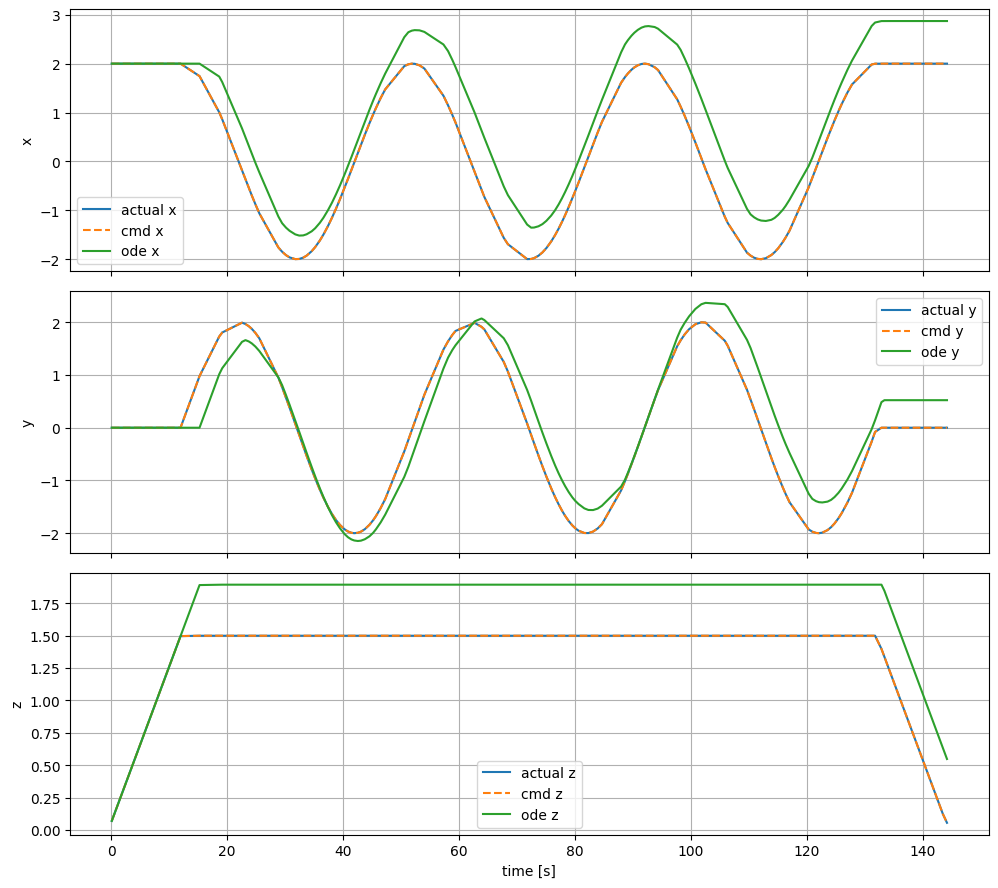

In [ ]:
example_run = test_sim["run_file"].unique()[0]
plot_df = test_sim[test_sim["run_file"] == example_run].copy()
t = plot_df["t"].to_numpy()

fig, axes = plt.subplots(3, 1, figsize=(10, 9), sharex=True)

axes[0].plot(t, plot_df["x"], label="actual x")
axes[0].plot(t, plot_df["cmd_x"], "--", label="cmd x")
axes[0].plot(t, plot_df["x_sim"], label="ode x")
axes[0].set_ylabel("x")
axes[0].legend()
axes[0].grid(True)

axes[1].plot(t, plot_df["y"], label="actual y")
axes[1].plot(t, plot_df["cmd_y"], "--", label="cmd y")
axes[1].plot(t, plot_df["y_sim"], label="ode y")
axes[1].set_ylabel("y")
axes[1].legend()
axes[1].grid(True)

axes[2].plot(t, plot_df["z"], label="actual z")
axes[2].plot(t, plot_df["cmd_z"], "--", label="cmd z")
axes[2].plot(t, plot_df["z_sim"], label="ode z")
axes[2].set_ylabel("z")
axes[2].set_xlabel("time [s]")
axes[2].legend()
axes[2].grid(True)

plt.tight_layout()
plt.show()

## Summary of Part 1: Gazebo Simulation Prototype

This first part was used as an initial proof of concept before working with real drone data. The goal was to test whether drone motion could be represented as a time-dependent system and whether a simple model could reproduce basic trajectories.

The simulated trajectories include point-to-point, square, and circular motion. The point-to-point and square trajectories were used for training, while the circular trajectory was used for testing. This allowed us to check whether the model could generalize to a trajectory shape that was not used during training.

A simple first-order commanded-motion model was implemented. The model integrates command-derived velocities over time to estimate the drone position. The RMSE results show that the model follows the general motion trend, but the test error is higher than the training error, especially for the horizontal coordinates. This means that the simple physics-inspired baseline is not sufficient to accurately reproduce all drone trajectories.

This section is therefore useful as a baseline and as a first validation of the modeling idea, but it remains simplified. The simulated trajectories do not fully represent the behavior of a real quadrotor, and they may contain idealized or discontinuous motion. For this reason, the next parts of the project move toward real Tello drone telemetry and data-driven learning.


# DATA COLLECTION: REAL DRONE TEST

This section performs the first real-drone learning experiment using Tello telemetry. The uploaded CSV files contain real flight data with drone state measurements and control commands.

The code loads the CSV files, keeps the relevant state and command variables, computes the time difference between consecutive samples, removes abnormal sampling intervals, normalizes the data, and builds one-step training pairs.

The first model is a simple Neural ODE-style predictor that learns.

This experiment verifies that the data pipeline works and that the model can learn basic drone behavior such as yaw and altitude changes.

In [ ]:
from google.colab import files

uploaded = files.upload()
print("Uploaded files:", list(uploaded.keys()))

Saving forward_yaw_01.csv to forward_yaw_01.csv
Saving hover_03.csv to hover_03.csv
Saving left_yaw_01.csv to left_yaw_01.csv
Saving up_12_01.csv to up_12_01.csv
Saving yaw_left_12_01.csv to yaw_left_12_01.csv
Saving yaw_right_12_01.csv to yaw_right_12_01.csv
Uploaded files: ['forward_yaw_01.csv', 'hover_03.csv', 'left_yaw_01.csv', 'up_12_01.csv', 'yaw_left_12_01.csv', 'yaw_right_12_01.csv']


In [ ]:
import pandas as pd
file_names = list(uploaded.keys())

dfs = []
for f in file_names:
    df = pd.read_csv(f)
    df["source_file"] = f
    dfs.append(df)

data = pd.concat(dfs, ignore_index=True)

print("Total rows:", len(data))
print("Columns:", data.columns.tolist())
data.head()

Total rows: 329
Columns: ['pc_time', 'cmd_lr', 'cmd_fb', 'cmd_ud', 'cmd_yaw', 'pitch', 'roll', 'yaw', 'vgx', 'vgy', 'vgz', 'tof', 'h', 'bat', 'baro', 'time', 'agx', 'agy', 'agz', 'source_file']


,pc_time,cmd_lr,cmd_fb,cmd_ud,cmd_yaw,pitch,roll,yaw,vgx,vgy,vgz,tof,h,bat,baro,time,agx,agy,agz,source_file
0,1.776793e+09,0,0,0,0,0,0,-31,0,0,0,190,150,71,4.33,63,37.0,-24.0,-976.0,forward_yaw_01.csv
1,1.776793e+09,0,0,0,0,1,-1,-30,0,0,0,199,150,71,4.18,63,-15.0,24.0,-1016.0,forward_yaw_01.csv
2,1.776793e+09,0,0,0,0,1,-1,-30,0,0,0,202,150,71,4.15,63,16.0,-2.0,-1038.0,forward_yaw_01.csv
3,1.776793e+09,0,0,0,0,1,-1,-30,0,0,0,208,150,71,4.21,63,16.0,-16.0,-1003.0,forward_yaw_01.csv
4,1.776793e+09,0,0,0,0,1,-1,-31,0,0,0,210,150,71,4.21,63,34.0,-17.0,-992.0,forward_yaw_01.csv


In [ ]:

cols = [
    "pc_time",
    "yaw", "h", "vgx", "vgy", "vgz",
    "cmd_lr", "cmd_fb", "cmd_ud", "cmd_yaw"
]

data = data[cols]

data = data.apply(pd.to_numeric, errors='coerce')

data = data.dropna()
data = data.sort_values(by="pc_time").reset_index(drop=True)

print("Cleaned rows:", len(data))
data.head()

Cleaned rows: 329


,pc_time,yaw,h,vgx,vgy,vgz,cmd_lr,cmd_fb,cmd_ud,cmd_yaw
0,1.776793e+09,0,90,0,0,0,0,0,0,0
1,1.776793e+09,0,90,0,0,0,0,0,0,0
2,1.776793e+09,0,90,-1,0,0,0,0,0,0
3,1.776793e+09,0,90,-1,0,0,0,0,0,0
4,1.776793e+09,0,90,-1,0,0,0,0,0,0


In [ ]:

cols = [
    "source_file", "pc_time",
    "yaw", "h", "vgx", "vgy", "vgz",
    "cmd_lr", "cmd_fb", "cmd_ud", "cmd_yaw"
]

dfs = []
for f in file_names:
    df = pd.read_csv(f)
    df["source_file"] = f
    dfs.append(df)

data_full = pd.concat(dfs, ignore_index=True)

data = data_full[cols].copy()
data = data.apply(lambda col: pd.to_numeric(col, errors="coerce") if col.name != "source_file" else col)
data = data.dropna().reset_index(drop=True)

data = data.sort_values(by=["source_file", "pc_time"]).reset_index(drop=True)

print("Rows:", len(data))
print("Trajectories:", data["source_file"].nunique())
print(data["source_file"].value_counts())

data.head()

Rows: 329
Trajectories: 6
source_file
yaw_left_12_01.csv     57
left_yaw_01.csv        57
yaw_right_12_01.csv    57
forward_yaw_01.csv     56
up_12_01.csv           55
hover_03.csv           47
Name: count, dtype: int64


,source_file,pc_time,yaw,h,vgx,vgy,vgz,cmd_lr,cmd_fb,cmd_ud,cmd_yaw
0,forward_yaw_01.csv,1.776793e+09,-31,150,0,0,0,0,0,0,0
1,forward_yaw_01.csv,1.776793e+09,-30,150,0,0,0,0,0,0,0
2,forward_yaw_01.csv,1.776793e+09,-30,150,0,0,0,0,0,0,0
3,forward_yaw_01.csv,1.776793e+09,-30,150,0,0,0,0,0,0,0
4,forward_yaw_01.csv,1.776793e+09,-31,150,0,0,0,0,0,0,0


In [ ]:
import numpy as np

# Compute time difference inside each trajectory
data["dt"] = data.groupby("source_file")["pc_time"].diff()

# Keep only rows with valid positive dt
data = data[(data["dt"].notna()) & (data["dt"] > 0)].copy()

print("Rows after dt filtering:", len(data))
print("dt stats:")
print(data["dt"].describe())

data[["source_file", "pc_time", "dt"]].head(10)

Rows after dt filtering: 323
dt stats:
count    323.000000
mean       0.101365
std        0.085240
min        0.000096
25%        0.051136
50%        0.101929
75%        0.102191
max        0.507761
Name: dt, dtype: float64


,source_file,pc_time,dt
1,forward_yaw_01.csv,1.776793e+09,0.101850
2,forward_yaw_01.csv,1.776793e+09,0.102068
3,forward_yaw_01.csv,1.776793e+09,0.102139
4,forward_yaw_01.csv,1.776793e+09,0.101953
5,forward_yaw_01.csv,1.776793e+09,0.101932
6,forward_yaw_01.csv,1.776793e+09,0.102047
7,forward_yaw_01.csv,1.776793e+09,0.102002
8,forward_yaw_01.csv,1.776793e+09,0.101963
9,forward_yaw_01.csv,1.776793e+09,0.155994
10,forward_yaw_01.csv,1.776793e+09,0.047974


In [ ]:
# Keep only reasonable dt (remove glitches)
data = data[(data["dt"] > 0.02) & (data["dt"] < 0.2)].copy()

print("Rows after dt cleaning:", len(data))

# Define state and input
state_cols = ["yaw", "h", "vgx", "vgy", "vgz"]
input_cols = ["cmd_lr", "cmd_fb", "cmd_ud", "cmd_yaw"]

# Normalize (simple mean/std)
mean_state = data[state_cols].mean()
std_state = data[state_cols].std()

mean_input = data[input_cols].mean()
std_input = data[input_cols].std()

# Avoid division by zero
std_state = std_state.replace(0, 1)
std_input = std_input.replace(0, 1)

data[state_cols] = (data[state_cols] - mean_state) / std_state
data[input_cols] = (data[input_cols] - mean_input) / std_input

print("Normalization done")
data.head()

Rows after dt cleaning: 261
Normalization done


,source_file,pc_time,yaw,h,vgx,vgy,vgz,cmd_lr,cmd_fb,cmd_ud,cmd_yaw,dt
1,forward_yaw_01.csv,1.776793e+09,-1.685627,0.883083,-0.21569,-0.365465,-0.256755,-0.177481,-0.219108,-0.165691,-0.185458,0.101850
2,forward_yaw_01.csv,1.776793e+09,-1.685627,0.883083,-0.21569,-0.365465,-0.256755,-0.177481,-0.219108,-0.165691,-0.185458,0.102068
3,forward_yaw_01.csv,1.776793e+09,-1.685627,0.883083,-0.21569,-0.365465,-0.256755,-0.177481,-0.219108,-0.165691,-0.185458,0.102139
4,forward_yaw_01.csv,1.776793e+09,-1.763729,0.883083,-0.21569,-0.365465,-0.256755,-0.177481,-0.219108,-0.165691,-0.185458,0.101953
5,forward_yaw_01.csv,1.776793e+09,-1.763729,0.883083,-0.21569,-0.365465,-0.256755,-0.177481,-0.219108,-0.165691,-0.185458,0.101932


In [ ]:
import numpy as np

state_cols = ["yaw", "h", "vgx", "vgy", "vgz"]
input_cols = ["cmd_lr", "cmd_fb", "cmd_ud", "cmd_yaw"]

X_list = []
U_list = []
DT_list = []
Y_list = []

for source_file, g in data.groupby("source_file"):
    g = g.sort_values("pc_time").reset_index(drop=True)

    x = g[state_cols].values
    u = g[input_cols].values
    dt = g["dt"].values

    # build x_t, u_t, dt_t -> x_{t+1}
    for i in range(len(g) - 1):
        X_list.append(x[i])
        U_list.append(u[i])
        DT_list.append(dt[i + 1])   # dt associated with next step
        Y_list.append(x[i + 1])

X = np.array(X_list, dtype=np.float32)
U = np.array(U_list, dtype=np.float32)
DT = np.array(DT_list, dtype=np.float32).reshape(-1, 1)
Y = np.array(Y_list, dtype=np.float32)

print("X shape:", X.shape)
print("U shape:", U.shape)
print("DT shape:", DT.shape)
print("Y shape:", Y.shape)

print("Sample X[0]:", X[0])
print("Sample U[0]:", U[0])
print("Sample DT[0]:", DT[0])
print("Sample Y[0]:", Y[0])

X shape: (255, 5)
U shape: (255, 4)
DT shape: (255, 1)
Y shape: (255, 5)
Sample X[0]: [-1.685627    0.883083   -0.21569014 -0.36546478 -0.2567546 ]
Sample U[0]: [-0.17748071 -0.21910757 -0.16569087 -0.18545824]
Sample DT[0]: [0.10206795]
Sample Y[0]: [-1.685627    0.883083   -0.21569014 -0.36546478 -0.2567546 ]


In [ ]:
import torch
from sklearn.model_selection import train_test_split

# Split
X_train, X_test, U_train, U_test, DT_train, DT_test, Y_train, Y_test = train_test_split(
    X, U, DT, Y, test_size=0.2, random_state=42
)

# Convert to torch tensors
X_train = torch.tensor(X_train, dtype=torch.float32)
U_train = torch.tensor(U_train, dtype=torch.float32)
DT_train = torch.tensor(DT_train, dtype=torch.float32)
Y_train = torch.tensor(Y_train, dtype=torch.float32)

X_test = torch.tensor(X_test, dtype=torch.float32)
U_test = torch.tensor(U_test, dtype=torch.float32)
DT_test = torch.tensor(DT_test, dtype=torch.float32)
Y_test = torch.tensor(Y_test, dtype=torch.float32)

print("Train size:", X_train.shape[0])
print("Test size:", X_test.shape[0])

print("X_train:", X_train.shape)
print("U_train:", U_train.shape)
print("DT_train:", DT_train.shape)
print("Y_train:", Y_train.shape)


Train size: 204
Test size: 51
X_train: torch.Size([204, 5])
U_train: torch.Size([204, 4])
DT_train: torch.Size([204, 1])
Y_train: torch.Size([204, 5])


In [ ]:
import torch.nn as nn

class ODEFunc(nn.Module):
    def __init__(self, state_dim, input_dim, hidden_dim=64):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(state_dim + input_dim, hidden_dim),
            nn.Tanh(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.Tanh(),
            nn.Linear(hidden_dim, state_dim)
        )

    def forward(self, x, u):
        xu = torch.cat([x, u], dim=1)
        return self.net(xu)


class NeuralODE(nn.Module):
    def __init__(self, state_dim, input_dim):
        super().__init__()
        self.func = ODEFunc(state_dim, input_dim)

    def forward(self, x, u, dt):
        dx = self.func(x, u)
        x_next = x + dx * dt
        return x_next


# Create model
state_dim = 5
input_dim = 4

model = NeuralODE(state_dim, input_dim)

print(model)

NeuralODE(
  (func): ODEFunc(
    (net): Sequential(
      (0): Linear(in_features=9, out_features=64, bias=True)
      (1): Tanh()
      (2): Linear(in_features=64, out_features=64, bias=True)
      (3): Tanh()
      (4): Linear(in_features=64, out_features=5, bias=True)
    )
  )
)


In [ ]:
import torch.optim as optim

optimizer = optim.Adam(model.parameters(), lr=1e-3)
loss_fn = nn.MSELoss()

epochs = 200

for epoch in range(epochs):
    model.train()

    optimizer.zero_grad()

    pred = model(X_train, U_train, DT_train)
    loss = loss_fn(pred, Y_train)

    loss.backward()
    optimizer.step()

    if epoch % 20 == 0:
        model.eval()
        with torch.no_grad():
            test_pred = model(X_test, U_test, DT_test)
            test_loss = loss_fn(test_pred, Y_test)

        print(f"Epoch {epoch} | Train Loss: {loss.item():.6f} | Test Loss: {test_loss.item():.6f}")

Epoch 0 | Train Loss: 0.295124 | Test Loss: 0.375649
Epoch 20 | Train Loss: 0.280818 | Test Loss: 0.373495
Epoch 40 | Train Loss: 0.268105 | Test Loss: 0.372266
Epoch 60 | Train Loss: 0.258959 | Test Loss: 0.373486
Epoch 80 | Train Loss: 0.254198 | Test Loss: 0.375449
Epoch 100 | Train Loss: 0.251666 | Test Loss: 0.376540
Epoch 120 | Train Loss: 0.249221 | Test Loss: 0.375907
Epoch 140 | Train Loss: 0.246243 | Test Loss: 0.375088
Epoch 160 | Train Loss: 0.242613 | Test Loss: 0.374662
Epoch 180 | Train Loss: 0.238597 | Test Loss: 0.375327


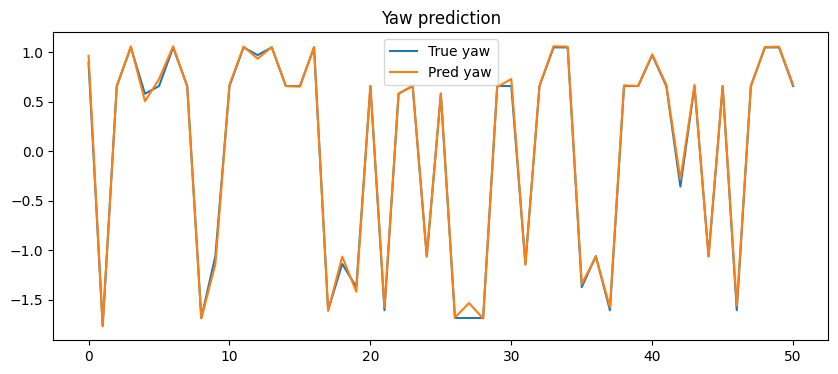

In [ ]:
import matplotlib.pyplot as plt

model.eval()

with torch.no_grad():
    pred = model(X_test, U_test, DT_test)

# pick one dimension (yaw = index 0)
plt.figure(figsize=(10,4))
plt.plot(Y_test[:,0].numpy(), label="True yaw")
plt.plot(pred[:,0].numpy(), label="Pred yaw")
plt.legend()
plt.title("Yaw prediction")
plt.show()

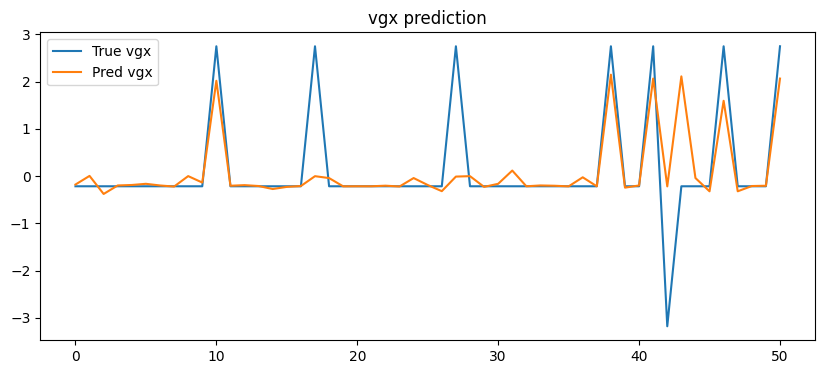

In [ ]:
plt.figure(figsize=(10,4))
plt.plot(Y_test[:,2].numpy(), label="True vgx")
plt.plot(pred[:,2].numpy(), label="Pred vgx")
plt.legend()
plt.title("vgx prediction")
plt.show()

## Summary of Part 2: First Real Drone Learning Experiment

This part introduces real telemetry collected from the DJI Tello drone. The uploaded CSV files contain flight measurements such as yaw, height, velocity components, and control commands. Compared with the previous simulated trajectories, this data is more realistic because it comes from actual drone behavior.

The data was cleaned by keeping only useful variables, converting values to numerical format, sorting samples by time, computing the time step , and removing abnormal sampling intervals. The state vector used in this first experiment is:


x = [yaw, h, vgx, vgy, vgz]


and the control vector is:

\[
u = [cmd_{lr}, cmd_{fb}, cmd_{ud}, cmd_{yaw}]
\]

The learning problem was formulated as a supervised next-state prediction task.


A first Neural ODE-style model was trained to predict the next state from the current state, control input, and time step. This model confirmed that the data pipeline works and that the drone telemetry can be used for learning. However, the dataset is small, with only a few hundred samples, and the test loss remains relatively high. Therefore, this part should be considered an exploratory experiment rather than the final model.

The result motivates the need for a larger, cleaner dataset and a more robust Controlled Neural ODE architecture, which is developed in the following sections.


## Part 3: Advanced Controlled Neural ODE

This section improves the first Neural ODE experiment by using a more advanced controlled continuous-time formulation.

The state vector is:

$$
x = [yaw, h, vgx, vgy, vgz]
$$

The control vector is:

$$
u = [cmd\_lr, cmd\_fb, cmd\_ud, cmd\_yaw]
$$

The data is cleaned, converted into current-state, control, time-step, and next-state training pairs, then normalized before training.

The model learns the continuous-time dynamics:

$$
dx/dt = f_\theta(x,u)
$$

This section evaluates one-step prediction performance by comparing predicted and measured yaw, height, and velocity values.


In [ ]:
!pip install torchdiffeq pandas numpy matplotlib scikit-learn -q


In [ ]:
from google.colab import files
uploaded = files.upload()

Saving forward_clean_02_trimmed.csv to forward_clean_02_trimmed.csv
Saving forward_yaw_01.csv to forward_yaw_01 (2).csv
Saving hover_03.csv to hover_03 (2).csv
Saving left_yaw_01.csv to left_yaw_01 (2).csv
Saving up_12_01.csv to up_12_01 (2).csv
Saving yaw_left_12_01.csv to yaw_left_12_01 (2).csv
Saving yaw_right_12_01.csv to yaw_right_12_01 (2).csv


In [ ]:
import pandas as pd
import numpy as np

files = [
    "hover_03.csv",
    "up_12_01.csv",
    "yaw_left_12_01.csv",
    "yaw_right_12_01.csv",
    "forward_yaw_01.csv",
    "left_yaw_01.csv",
    "forward_clean_02_trimmed.csv"
]

dfs = []

for f in files:
    df = pd.read_csv(f)
    df["source"] = f  # keep track of trajectory
    dfs.append(df)

# Merge all
data = pd.concat(dfs, ignore_index=True)

print("Total samples:", len(data))
data.head()

Total samples: 576


,pc_time,cmd_lr,cmd_fb,cmd_ud,cmd_yaw,pitch,roll,yaw,vgx,vgy,vgz,tof,h,bat,baro,time,agx,agy,agz,source
0,1.776857e+09,0.0,0.0,0.0,0.0,0,0,147,0,0,0,131,130,87,23.80,15,2.0,-3.0,-999.0,hover_03.csv
1,1.776857e+09,0.0,0.0,0.0,0.0,0,0,147,0,0,0,131,130,87,23.90,15,-4.0,0.0,-1004.0,hover_03.csv
2,1.776857e+09,0.0,0.0,0.0,0.0,0,0,147,0,0,0,131,130,87,23.82,15,10.0,10.0,-1001.0,hover_03.csv
3,1.776857e+09,0.0,0.0,0.0,0.0,0,0,147,0,0,0,131,130,87,23.85,15,-4.0,3.0,-999.0,hover_03.csv
4,1.776857e+09,0.0,0.0,0.0,0.0,0,0,147,0,0,0,131,130,87,23.79,16,-11.0,33.0,-992.0,hover_03.csv


In [ ]:
print(data.columns)

Index(['pc_time', 'cmd_lr', 'cmd_fb', 'cmd_ud', 'cmd_yaw', 'pitch', 'roll',
       'yaw', 'vgx', 'vgy', 'vgz', 'tof', 'h', 'bat', 'baro', 'time', 'agx',
       'agy', 'agz', 'source'],
      dtype='object')


In [ ]:

state_cols = ["yaw", "h", "vgx", "vgy", "vgz"]
input_cols = ["cmd_lr", "cmd_fb", "cmd_ud", "cmd_yaw"]
keep_cols = ["source", "pc_time"] + state_cols + input_cols

data = data[keep_cols].copy()

# Convert numeric columns safely
for c in keep_cols:
    if c != "source":
        data[c] = pd.to_numeric(data[c], errors="coerce")

# Drop bad rows
data = data.dropna().reset_index(drop=True)

# Sort inside each trajectory
data = data.sort_values(["source", "pc_time"]).reset_index(drop=True)

print("Clean samples:", len(data))
print("Trajectories:", data["source"].nunique())
print(data["source"].value_counts())

data.head()

Clean samples: 576
Trajectories: 7
source
forward_clean_02_trimmed.csv    248
left_yaw_01.csv                  59
yaw_left_12_01.csv               57
yaw_right_12_01.csv              56
forward_yaw_01.csv               55
up_12_01.csv                     54
hover_03.csv                     47
Name: count, dtype: int64


,source,pc_time,yaw,h,vgx,vgy,vgz,cmd_lr,cmd_fb,cmd_ud,cmd_yaw
0,forward_clean_02_trimmed.csv,1.776867e+09,0,80,0,0,0,0.0,0.0,0.0,0.0
1,forward_clean_02_trimmed.csv,1.776867e+09,0,80,0,0,0,0.0,0.0,0.0,0.0
2,forward_clean_02_trimmed.csv,1.776867e+09,0,80,0,0,0,0.0,0.0,0.0,0.0
3,forward_clean_02_trimmed.csv,1.776867e+09,0,80,0,0,0,0.0,0.0,0.0,0.0
4,forward_clean_02_trimmed.csv,1.776867e+09,0,80,0,0,0,0.0,0.0,0.0,0.0


In [ ]:
# Keep only the variables we want
state_cols = ["yaw", "h", "vgx", "vgy", "vgz"]
input_cols = ["cmd_lr", "cmd_fb", "cmd_ud", "cmd_yaw"]
keep_cols = ["source", "pc_time"] + state_cols + input_cols

data = data[keep_cols].copy()

# Convert numeric columns safely
for c in keep_cols:
    if c != "source":
        data[c] = pd.to_numeric(data[c], errors="coerce")

# Drop bad rows
data = data.dropna().reset_index(drop=True)

# Sort inside each trajectory
data = data.sort_values(["source", "pc_time"]).reset_index(drop=True)

print("Clean samples:", len(data))
print("Trajectories:", data["source"].nunique())
print(data["source"].value_counts())

data.head()

Clean samples: 576
Trajectories: 7
source
forward_clean_02_trimmed.csv    248
left_yaw_01.csv                  59
yaw_left_12_01.csv               57
yaw_right_12_01.csv              56
forward_yaw_01.csv               55
up_12_01.csv                     54
hover_03.csv                     47
Name: count, dtype: int64


,source,pc_time,yaw,h,vgx,vgy,vgz,cmd_lr,cmd_fb,cmd_ud,cmd_yaw
0,forward_clean_02_trimmed.csv,1.776867e+09,0,80,0,0,0,0.0,0.0,0.0,0.0
1,forward_clean_02_trimmed.csv,1.776867e+09,0,80,0,0,0,0.0,0.0,0.0,0.0
2,forward_clean_02_trimmed.csv,1.776867e+09,0,80,0,0,0,0.0,0.0,0.0,0.0
3,forward_clean_02_trimmed.csv,1.776867e+09,0,80,0,0,0,0.0,0.0,0.0,0.0
4,forward_clean_02_trimmed.csv,1.776867e+09,0,80,0,0,0,0.0,0.0,0.0,0.0


In [ ]:
# Compute dt (time difference) per trajectory
data["dt"] = data.groupby("source")["pc_time"].diff()

# Remove first rows of each trajectory (dt = NaN)
data = data.dropna().reset_index(drop=True)

# Remove weird dt values (very small or very large)
data = data[(data["dt"] > 0.01) & (data["dt"] < 0.2)]

print("After dt cleaning:", len(data))
print(data["dt"].describe())

data.head()

After dt cleaning: 505
count    505.000000
mean       0.098757
std        0.018410
min        0.012462
25%        0.099954
50%        0.100292
75%        0.101978
max        0.191144
Name: dt, dtype: float64


,source,pc_time,yaw,h,vgx,vgy,vgz,cmd_lr,cmd_fb,cmd_ud,cmd_yaw,dt
0,forward_clean_02_trimmed.csv,1.776867e+09,0,80,0,0,0,0.0,0.0,0.0,0.0,0.099933
1,forward_clean_02_trimmed.csv,1.776867e+09,0,80,0,0,0,0.0,0.0,0.0,0.0,0.150543
2,forward_clean_02_trimmed.csv,1.776867e+09,0,80,0,0,0,0.0,0.0,0.0,0.0,0.099722
3,forward_clean_02_trimmed.csv,1.776867e+09,0,80,0,0,0,0.0,0.0,0.0,0.0,0.099991
4,forward_clean_02_trimmed.csv,1.776867e+09,0,80,0,0,0,0.0,0.0,0.0,0.0,0.100384


In [ ]:
import numpy as np

X_list, U_list, Y_list, DT_list = [], [], [], []

for traj in data["source"].unique():
    df = data[data["source"] == traj]

    X = df[state_cols].values[:-1]
    U = df[input_cols].values[:-1]
    Y = df[state_cols].values[1:]
    DT = df["dt"].values[:-1].reshape(-1, 1)

    X_list.append(X)
    U_list.append(U)
    Y_list.append(Y)
    DT_list.append(DT)

# Concatenate all trajectories
X = np.vstack(X_list)
U = np.vstack(U_list)
Y = np.vstack(Y_list)
DT = np.vstack(DT_list)

print("X:", X.shape)
print("U:", U.shape)
print("Y:", Y.shape)
print("DT:", DT.shape)

print("Sample X:", X[0])
print("Sample U:", U[0])
print("Sample DT:", DT[0])
print("Sample Y:", Y[0])

X: (498, 5)
U: (498, 4)
Y: (498, 5)
DT: (498, 1)
Sample X: [ 0 80  0  0  0]
Sample U: [0. 0. 0. 0.]
Sample DT: [0.09993267]
Sample Y: [ 0 80  0  0  0]


In [ ]:
from sklearn.model_selection import train_test_split

# Normalize
X_mean = X.mean(axis=0)
X_std = X.std(axis=0) + 1e-6

U_mean = U.mean(axis=0)
U_std = U.std(axis=0) + 1e-6

Y_mean = Y.mean(axis=0)
Y_std = Y.std(axis=0) + 1e-6

Xn = (X - X_mean) / X_std
Un = (U - U_mean) / U_std
Yn = (Y - Y_mean) / Y_std

# Split
X_train, X_test, U_train, U_test, Y_train, Y_test, DT_train, DT_test = train_test_split(
    Xn, Un, Yn, DT, test_size=0.2, random_state=42
)

print("Train:", X_train.shape, U_train.shape, Y_train.shape, DT_train.shape)
print("Test :", X_test.shape, U_test.shape, Y_test.shape, DT_test.shape)

Train: (398, 5) (398, 4) (398, 5) (398, 1)
Test : (100, 5) (100, 4) (100, 5) (100, 1)


In [ ]:
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

X_train_t = torch.tensor(X_train, dtype=torch.float32).to(device)
U_train_t = torch.tensor(U_train, dtype=torch.float32).to(device)
Y_train_t = torch.tensor(Y_train, dtype=torch.float32).to(device)
DT_train_t = torch.tensor(DT_train, dtype=torch.float32).to(device)

X_test_t = torch.tensor(X_test, dtype=torch.float32).to(device)
U_test_t = torch.tensor(U_test, dtype=torch.float32).to(device)
Y_test_t = torch.tensor(Y_test, dtype=torch.float32).to(device)
DT_test_t = torch.tensor(DT_test, dtype=torch.float32).to(device)

print(X_train_t.shape, U_train_t.shape, Y_train_t.shape, DT_train_t.shape)
print(X_test_t.shape, U_test_t.shape, Y_test_t.shape, DT_test_t.shape)

Device: cpu
torch.Size([398, 5]) torch.Size([398, 4]) torch.Size([398, 5]) torch.Size([398, 1])
torch.Size([100, 5]) torch.Size([100, 4]) torch.Size([100, 5]) torch.Size([100, 1])


In [ ]:
import torch.nn as nn
from torchdiffeq import odeint


class ControlledODEFunc(nn.Module):
    def __init__(self, state_dim=5, input_dim=4, hidden_dim=128):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(state_dim + input_dim, hidden_dim),
            nn.Tanh(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.Tanh(),
            nn.Linear(hidden_dim, state_dim)
        )
        self.u = None

    def set_control(self, u):
        self.u = u

    def forward(self, t, x):
        xu = torch.cat([x, self.u], dim=1)
        return self.net(xu)


class NeuralODEModel(nn.Module):
    def __init__(self, state_dim=5, input_dim=4, hidden_dim=128):
        super().__init__()
        self.func = ControlledODEFunc(state_dim, input_dim, hidden_dim)

    def forward(self, x0, u, dt):
        self.func.set_control(u)
        t = torch.cat(
            [torch.zeros(1, device=x0.device), dt.view(1)]
        )
        out = odeint(self.func, x0, t, method="rk4")
        return out[-1]


model = NeuralODEModel().to(device)
print(model)

NeuralODEModel(
  (func): ControlledODEFunc(
    (net): Sequential(
      (0): Linear(in_features=9, out_features=128, bias=True)
      (1): Tanh()
      (2): Linear(in_features=128, out_features=128, bias=True)
      (3): Tanh()
      (4): Linear(in_features=128, out_features=5, bias=True)
    )
  )
)


In [ ]:
import torch.optim as optim

optimizer = optim.Adam(model.parameters(), lr=1e-3)
loss_fn = nn.MSELoss()

num_epochs = 300
train_losses = []
test_losses = []

for epoch in range(num_epochs):
    model.train()

    optimizer.zero_grad()
    pred_train = model(X_train_t, U_train_t, DT_train_t[0])
    loss_train = loss_fn(pred_train, Y_train_t)
    loss_train.backward()
    optimizer.step()

    model.eval()
    with torch.no_grad():
        pred_test = model(X_test_t, U_test_t, DT_test_t[0])
        loss_test = loss_fn(pred_test, Y_test_t)

    train_losses.append(loss_train.item())
    test_losses.append(loss_test.item())

    if epoch % 20 == 0:
        print(f"Epoch {epoch:03d} | Train Loss: {loss_train.item():.6f} | Test Loss: {loss_test.item():.6f}")

Epoch 000 | Train Loss: 0.142142 | Test Loss: 0.008546
Epoch 020 | Train Loss: 0.141814 | Test Loss: 0.007696
Epoch 040 | Train Loss: 0.141279 | Test Loss: 0.007948
Epoch 060 | Train Loss: 0.140995 | Test Loss: 0.008231
Epoch 080 | Train Loss: 0.140825 | Test Loss: 0.008261
Epoch 100 | Train Loss: 0.140709 | Test Loss: 0.008366
Epoch 120 | Train Loss: 0.140623 | Test Loss: 0.008445
Epoch 140 | Train Loss: 0.140551 | Test Loss: 0.008524
Epoch 160 | Train Loss: 0.140485 | Test Loss: 0.008599
Epoch 180 | Train Loss: 0.140420 | Test Loss: 0.008674
Epoch 200 | Train Loss: 0.140349 | Test Loss: 0.008752
Epoch 220 | Train Loss: 0.140263 | Test Loss: 0.008829
Epoch 240 | Train Loss: 0.140165 | Test Loss: 0.009020
Epoch 260 | Train Loss: 0.140030 | Test Loss: 0.008871
Epoch 280 | Train Loss: 0.139942 | Test Loss: 0.009523


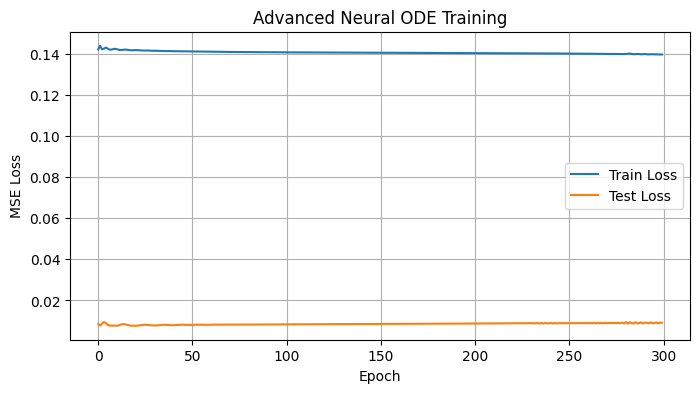

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 4))
plt.plot(train_losses, label="Train Loss")
plt.plot(test_losses, label="Test Loss")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("Advanced Neural ODE Training")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
model.eval()
with torch.no_grad():
    pred_test = model(X_test_t, U_test_t, DT_test_t[0]).cpu().numpy()

Y_test_np = Y_test_t.cpu().numpy()

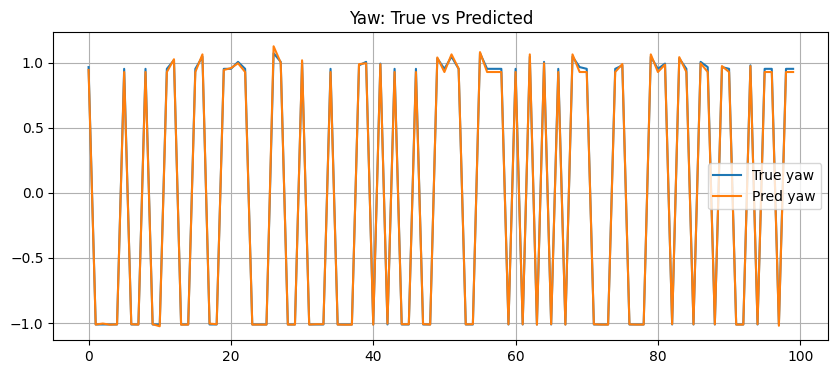

In [ ]:
plt.figure(figsize=(10, 4))
plt.plot(Y_test_np[:, 0], label="True yaw")
plt.plot(pred_test[:, 0], label="Pred yaw")
plt.title("Yaw: True vs Predicted")
plt.legend()
plt.grid(True)
plt.show()

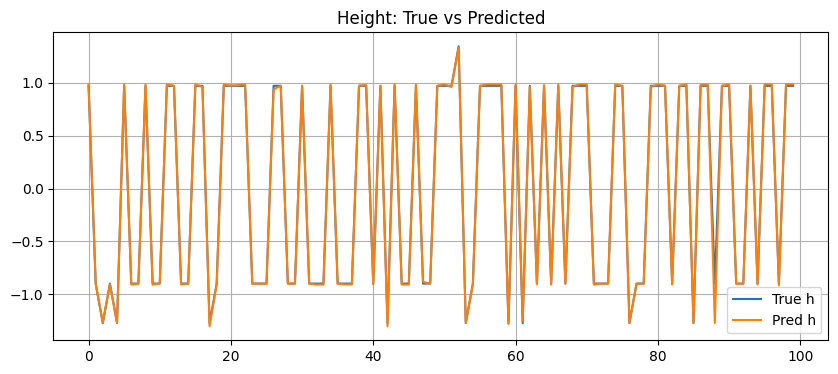

In [ ]:
plt.figure(figsize=(10, 4))
plt.plot(Y_test_np[:, 1], label="True h")
plt.plot(pred_test[:, 1], label="Pred h")
plt.title("Height: True vs Predicted")
plt.legend()
plt.grid(True)
plt.show()

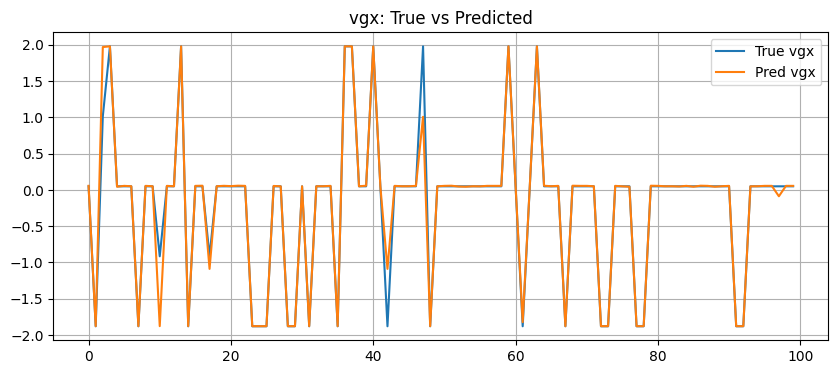

In [ ]:
plt.figure(figsize=(10, 4))
plt.plot(Y_test_np[:, 2], label="True vgx")
plt.plot(pred_test[:, 2], label="Pred vgx")
plt.title("vgx: True vs Predicted")
plt.legend()
plt.grid(True)
plt.show()

## Summary of Part 3: Advanced Controlled Neural ODE

This part improves the first real-drone learning experiment by using a more explicit continuous-time formulation. Instead of only applying a simple one-step update, the model learns a continuous dynamics function.

The model learns:

$$
dx/dt = f_\theta(x,u)
$$

where `x` is the drone state and `u` is the control input. The learned derivative is then integrated over the sampling time step to predict the next state.

The state vector is:

$$
x = [yaw, h, vgx, vgy, vgz]
$$

The control vector is:

$$
u = [cmd\_lr, cmd\_fb, cmd\_ud, cmd\_yaw]
$$

This advanced formulation is closer to the idea of a digital twin because it models the drone as a continuous-time dynamical system. The training results show lower test loss compared with the first experiment, which indicates that the model can learn short-term drone behavior more effectively.

However, the experiment still has limitations. The dataset is still relatively small, and the train/test split may contain different trajectory distributions. Also, the model is evaluated mainly on one-step prediction, which is easier than long-term simulation. Because a digital twin must simulate future behavior over many steps, the final part of the notebook introduces a larger dataset and multi-step rollout evaluation.


### Part4: advanced data loading + cleaning + merging pipeline

This section is the final cleaned data pipeline used for the main model. Instead of uploading files manually, the dataset is loaded directly from Google Drive. This makes the workflow reproducible and allows the notebook to be rerun without re-uploading data.

The selected CSV files correspond to the best real Tello flight experiments collected through ROS 2. The code merges these files, removes invalid telemetry values, filters impossible height and velocity measurements, computes the sampling interval \(\Delta t\), and normalizes the state and control variables.

This produces the final dataset used for controlled Neural ODE training.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

DATA_PATH = "/content/drive/MyDrive/Last part ODE Data"

files = os.listdir(DATA_PATH)
print(files)

['yaw_left_clean_01.csv', 'forward_long_01.csv', 'yaw_left_clean_01_trimmed.csv', 'forward_clean_02_trimmed.csv', 'fb_oscillate_01.csv', 'yaw_cmd_01.csv', 'forward_yaw_cmd_02.csv', 'forward_clean_02.csv']


In [ ]:
import os

DATA_PATH = "/content/drive/MyDrive/Last part ODE Data"

files = sorted([f for f in os.listdir(DATA_PATH) if f.endswith(".csv")])

print("CSV files found:")
for f in files:
    print(f)

CSV files found:
fb_oscillate_01.csv
forward_clean_02.csv
forward_clean_02_trimmed.csv
forward_long_01.csv
forward_yaw_cmd_02.csv
yaw_cmd_01.csv
yaw_left_clean_01.csv
yaw_left_clean_01_trimmed.csv


In [ ]:
import os
import pandas as pd
import numpy as np

selected_files = [
    "fb_oscillate_01.csv",
    "forward_clean_02_trimmed.csv",
    "forward_yaw_cmd_02.csv",
    "yaw_cmd_01.csv",
]

dfs = []

for fname in selected_files:
    path = os.path.join(DATA_PATH, fname)
    df = pd.read_csv(path)
    df["source"] = fname
    dfs.append(df)

raw_data = pd.concat(dfs, ignore_index=True)

print("Loaded rows:", len(raw_data))
print("Columns:")
print(raw_data.columns.tolist())

raw_data.head()

Loaded rows: 3617
Columns:
['pc_time', 'cmd_lr', 'cmd_fb', 'cmd_ud', 'cmd_yaw', 'pitch', 'roll', 'yaw', 'vgx', 'vgy', 'vgz', 'tof', 'h', 'bat', 'baro', 'time', 'agx', 'agy', 'agz', 'source']


,pc_time,cmd_lr,cmd_fb,cmd_ud,cmd_yaw,pitch,roll,yaw,vgx,vgy,vgz,tof,h,bat,baro,time,agx,agy,agz,source
0,1.776937e+09,0.0,0.0,0.0,0.0,0,0,-91,0,0,0,6553,0,76,-25.10,17,6.0,2.0,-997.0,fb_oscillate_01.csv
1,1.776937e+09,0.0,0.0,0.0,0.0,0,0,-91,0,0,0,6553,0,76,-25.07,17,5.0,2.0,-995.0,fb_oscillate_01.csv
2,1.776937e+09,0.0,0.0,0.0,0.0,0,0,-91,0,0,0,6553,0,76,-25.09,17,4.0,4.0,-1000.0,fb_oscillate_01.csv
3,1.776937e+09,0.0,0.0,0.0,0.0,0,0,-91,0,0,0,6553,0,76,-25.04,17,5.0,3.0,-999.0,fb_oscillate_01.csv
4,1.776937e+09,0.0,0.0,0.0,0.0,0,0,-91,0,0,0,6553,0,76,-25.03,17,5.0,3.0,-1001.0,fb_oscillate_01.csv


In [ ]:
# Copy raw data
df = raw_data.copy()

# Remove invalid TOF values
df = df[df["tof"] < 1000]

# Remove impossible height values
df = df[(df["h"] >= 0) & (df["h"] < 300)]

# Remove extreme velocities
for col in ["vgx", "vgy", "vgz"]:
    df = df[(df[col] > -200) & (df[col] < 200)]

# Sort by time
df = df.sort_values("pc_time").reset_index(drop=True)

# Compute dt
df["dt"] = df["pc_time"].diff().fillna(0.1)

# Remove weird dt jumps
df = df[(df["dt"] > 0.01) & (df["dt"] < 1.0)]

# Normalize yaw to [-180, 180]
df["yaw"] = ((df["yaw"] + 180) % 360) - 180

# Select features
state_cols = [
    "yaw",
    "h",
    "vgx",
    "vgy",
    "vgz"
]

control_cols = [
    "cmd_lr",
    "cmd_fb",
    "cmd_ud",
    "cmd_yaw"
]

# Final dataframe
model_df = df[state_cols + control_cols + ["dt"]].copy()

print("Clean rows:", len(model_df))
print(model_df.describe())

model_df.head()

Clean rows: 3205
               yaw            h          vgx          vgy          vgz  \
count  3205.000000  3205.000000  3205.000000  3205.000000  3205.000000   
mean    -65.945086    51.410296    -0.063651     0.274571    -0.003744   
std      47.798168    43.752030     0.572741     1.292007     1.081272   
min    -179.000000     0.000000   -14.000000   -13.000000    -9.000000   
25%     -92.000000     0.000000     0.000000     0.000000     0.000000   
50%     -91.000000    70.000000     0.000000     0.000000     0.000000   
75%     -49.000000    90.000000     0.000000     0.000000     0.000000   
max     178.000000   120.000000     5.000000     4.000000    20.000000   

       cmd_lr       cmd_fb       cmd_ud      cmd_yaw           dt  
count  3205.0  3205.000000  3205.000000  3205.000000  3205.000000  
mean      0.0    11.556942     0.519501    -0.084243     0.103059  
std       0.0    16.246875     2.743169     7.413194     0.038967  
min       0.0   -30.000000     0.000000   -3

,yaw,h,vgx,vgy,vgz,cmd_lr,cmd_fb,cmd_ud,cmd_yaw,dt
0,0,80,0,0,0,0.0,0.0,0.0,0.0,0.100000
1,0,80,0,0,0,0.0,0.0,0.0,0.0,0.099933
2,0,80,0,0,0,0.0,0.0,0.0,0.0,0.150543
3,0,80,0,0,0,0.0,0.0,0.0,0.0,0.099722
4,0,80,0,0,0,0.0,0.0,0.0,0.0,0.099991


In [ ]:
from sklearn.preprocessing import StandardScaler
import numpy as np

# -------------------------
# states and controls
# -------------------------

X_state = model_df[state_cols].values.astype(np.float32)
U_ctrl  = model_df[control_cols].values.astype(np.float32)
DT      = model_df["dt"].values.astype(np.float32)

# -------------------------
# normalize
# -------------------------

state_scaler = StandardScaler()
ctrl_scaler  = StandardScaler()

X_state_norm = state_scaler.fit_transform(X_state)
U_ctrl_norm  = ctrl_scaler.fit_transform(U_ctrl)

# -------------------------
# next-state prediction
# -------------------------

x_t      = X_state_norm[:-1]
u_t      = U_ctrl_norm[:-1]
dt_t     = DT[:-1]

x_next   = X_state_norm[1:]

# -------------------------
# train/test split
# keep temporal ordering
# -------------------------

split_idx = int(0.8 * len(x_t))

train_data = {
    "x": x_t[:split_idx],
    "u": u_t[:split_idx],
    "dt": dt_t[:split_idx],
    "y": x_next[:split_idx]
}

test_data = {
    "x": x_t[split_idx:],
    "u": u_t[split_idx:],
    "dt": dt_t[split_idx:],
    "y": x_next[split_idx:]
}

print("Train samples:", len(train_data["x"]))
print("Test samples :", len(test_data["x"]))

print("\nState shape:", train_data["x"].shape)
print("Control shape:", train_data["u"].shape)

Train samples: 2563
Test samples : 641

State shape: (2563, 5)
Control shape: (2563, 4)


In [ ]:
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

def to_tensor(x):
    return torch.tensor(x, dtype=torch.float32).to(device)

x_train = to_tensor(train_data["x"])
u_train = to_tensor(train_data["u"])
dt_train = to_tensor(train_data["dt"]).view(-1, 1)
y_train = to_tensor(train_data["y"])

x_test = to_tensor(test_data["x"])
u_test = to_tensor(test_data["u"])
dt_test = to_tensor(test_data["dt"]).view(-1, 1)
y_test = to_tensor(test_data["y"])

print(x_train.shape, u_train.shape, dt_train.shape, y_train.shape)
print(x_test.shape, u_test.shape, dt_test.shape, y_test.shape)

Device: cuda
torch.Size([2563, 5]) torch.Size([2563, 4]) torch.Size([2563, 1]) torch.Size([2563, 5])
torch.Size([641, 5]) torch.Size([641, 4]) torch.Size([641, 1]) torch.Size([641, 5])


In [ ]:
import torch.nn as nn
import torch.optim as optim

class ControlledODEFunc(nn.Module):
    def __init__(self, state_dim=5, control_dim=4, hidden_dim=128):
        super().__init__()

        self.net = nn.Sequential(
            nn.Linear(state_dim + control_dim, hidden_dim),
            nn.LayerNorm(hidden_dim),
            nn.Tanh(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.LayerNorm(hidden_dim),
            nn.Tanh(),
            nn.Linear(hidden_dim, state_dim)
        )

    def forward(self, x, u):
        xu = torch.cat([x, u], dim=-1)
        dxdt = self.net(xu)
        return dxdt


class ControlledNeuralODE(nn.Module):
    def __init__(self, state_dim=5, control_dim=4, hidden_dim=128):
        super().__init__()
        self.func = ControlledODEFunc(state_dim, control_dim, hidden_dim)

    def forward(self, x, u, dt):
        # RK4 integration, variable dt per sample
        k1 = self.func(x, u)
        k2 = self.func(x + 0.5 * dt * k1, u)
        k3 = self.func(x + 0.5 * dt * k2, u)
        k4 = self.func(x + dt * k3, u)

        x_next = x + (dt / 6.0) * (k1 + 2*k2 + 2*k3 + k4)
        return x_next


model = ControlledNeuralODE(
    state_dim=5,
    control_dim=4,
    hidden_dim=128
).to(device)

print(model)

ControlledNeuralODE(
  (func): ControlledODEFunc(
    (net): Sequential(
      (0): Linear(in_features=9, out_features=128, bias=True)
      (1): LayerNorm((128,), eps=1e-05, elementwise_affine=True)
      (2): Tanh()
      (3): Linear(in_features=128, out_features=128, bias=True)
      (4): LayerNorm((128,), eps=1e-05, elementwise_affine=True)
      (5): Tanh()
      (6): Linear(in_features=128, out_features=5, bias=True)
    )
  )
)


In [ ]:
import torch.nn.functional as F

with torch.no_grad():
    baseline_pred = x_test.clone()   # persistence baseline: x_next = x_t
    baseline_loss = F.mse_loss(baseline_pred, y_test)

print("Persistence baseline test MSE:", baseline_loss.item())

Persistence baseline test MSE: 0.07597808539867401


In [ ]:
optimizer = optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
loss_fn = nn.MSELoss()

epochs = 400
train_losses = []
test_losses = []

for epoch in range(epochs):
    model.train()
    optimizer.zero_grad()

    pred = model(x_train, u_train, dt_train)
    train_loss = loss_fn(pred, y_train)

    train_loss.backward()
    torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
    optimizer.step()

    model.eval()
    with torch.no_grad():
        test_pred = model(x_test, u_test, dt_test)
        test_loss = loss_fn(test_pred, y_test)

    train_losses.append(train_loss.item())
    test_losses.append(test_loss.item())

    if epoch % 25 == 0:
        print(
            f"Epoch {epoch:03d} | "
            f"Train Loss: {train_loss.item():.6f} | "
            f"Test Loss: {test_loss.item():.6f}"
        )

Epoch 000 | Train Loss: 0.223758 | Test Loss: 0.075815
Epoch 025 | Train Loss: 0.192474 | Test Loss: 0.077520
Epoch 050 | Train Loss: 0.183525 | Test Loss: 0.078920
Epoch 075 | Train Loss: 0.172843 | Test Loss: 0.077039
Epoch 100 | Train Loss: 0.160054 | Test Loss: 0.075288
Epoch 125 | Train Loss: 0.150188 | Test Loss: 0.074984
Epoch 150 | Train Loss: 0.143092 | Test Loss: 0.075746
Epoch 175 | Train Loss: 0.139454 | Test Loss: 0.076664
Epoch 200 | Train Loss: 0.132538 | Test Loss: 0.076774
Epoch 225 | Train Loss: 0.123952 | Test Loss: 0.077194
Epoch 250 | Train Loss: 0.119923 | Test Loss: 0.080176
Epoch 275 | Train Loss: 0.118738 | Test Loss: 0.080537
Epoch 300 | Train Loss: 0.110946 | Test Loss: 0.080620
Epoch 325 | Train Loss: 0.111602 | Test Loss: 0.085298
Epoch 350 | Train Loss: 0.108808 | Test Loss: 0.086572
Epoch 375 | Train Loss: 0.098859 | Test Loss: 0.081894


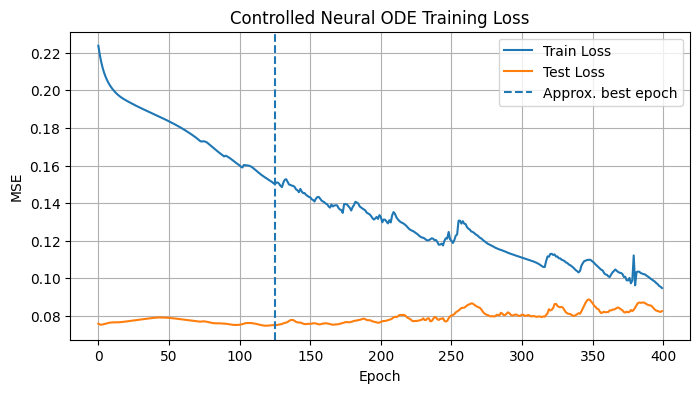

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,4))
plt.plot(train_losses, label="Train Loss")
plt.plot(test_losses, label="Test Loss")
plt.axvline(125, linestyle="--", label="Approx. best epoch")
plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.title("Controlled Neural ODE Training Loss")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
model.eval()
with torch.no_grad():
    pred_test = model(x_test, u_test, dt_test)

pred_np = pred_test.cpu().numpy()
true_np = y_test.cpu().numpy()

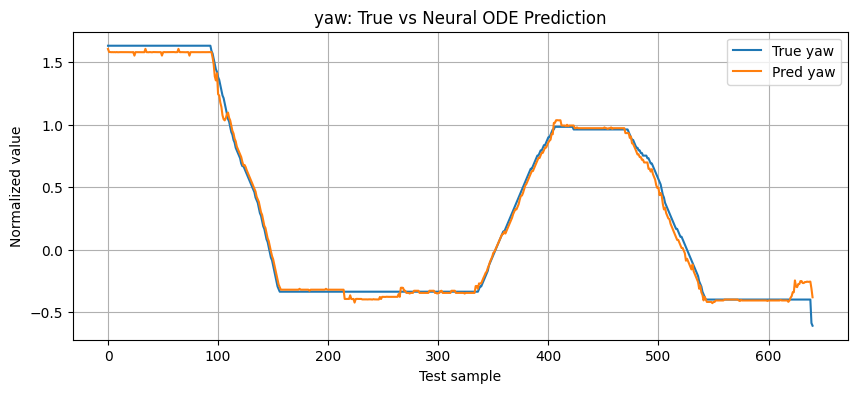

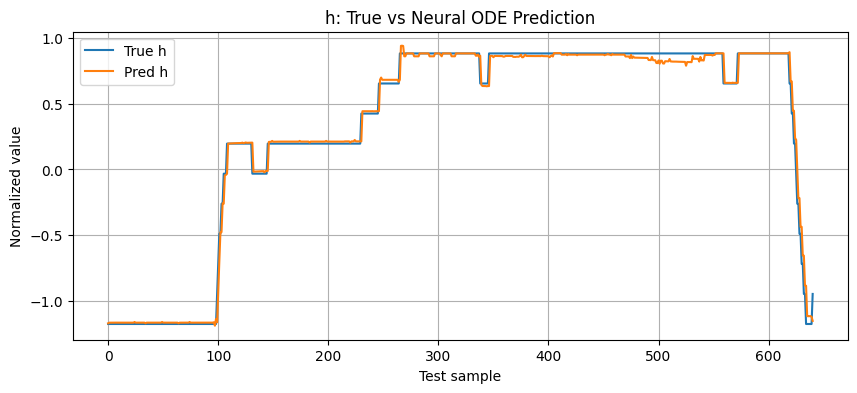

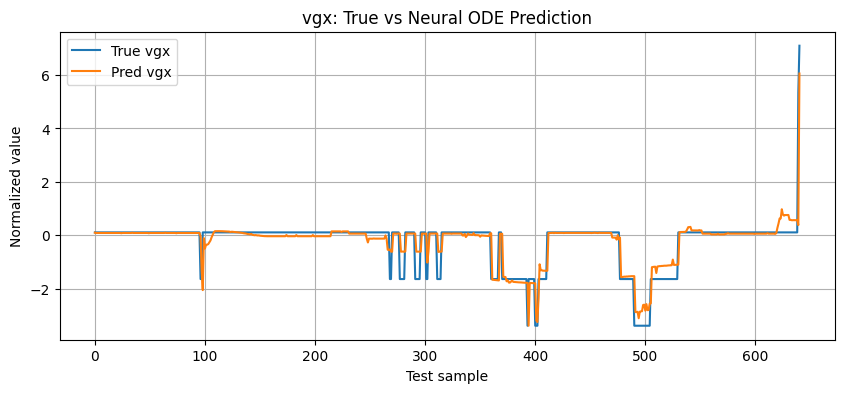

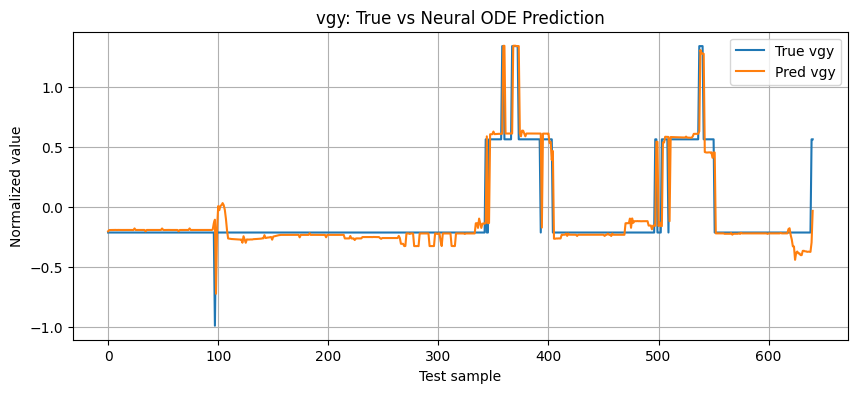

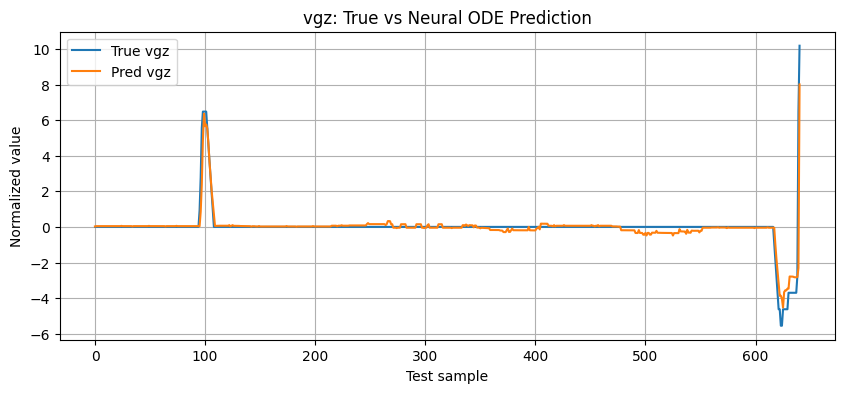

In [ ]:
plot_names = ["yaw", "h", "vgx", "vgy", "vgz"]

for i, name in enumerate(plot_names):
    plt.figure(figsize=(10,4))
    plt.plot(true_np[:, i], label=f"True {name}")
    plt.plot(pred_np[:, i], label=f"Pred {name}")
    plt.title(f"{name}: True vs Neural ODE Prediction")
    plt.xlabel("Test sample")
    plt.ylabel("Normalized value")
    plt.legend()
    plt.grid(True)
    plt.show()

In [ ]:
torch.save(model.state_dict(), "tello_neural_ode.pth")

## Summary of Part 4: Final Dataset Preparation

This part creates the final dataset used for the main Controlled Neural ODE model. Instead of manually uploading files, the data is loaded directly from Google Drive. This makes the workflow more reproducible and avoids problems caused by duplicate file names in Colab.

Four selected Tello flight recordings are used:

- forward/backward oscillation
- clean forward motion
- forward motion with yaw command
- yaw command experiment

The raw dataset contains 3617 samples. After cleaning invalid time-of-flight values, impossible height values, extreme velocity values, and abnormal time intervals, the final dataset contains 3205 samples.

The final state vector is:

$$
x = [yaw, h, vgx, vgy, vgz]
$$

The control vector is:

$$
u = [cmd\_lr, cmd\_fb, cmd\_ud, cmd\_yaw]
$$

The data is normalized using `StandardScaler`, then converted into next-state prediction pairs. The first 80% of samples are used for training and the last 20% are used for testing, preserving temporal order.

This dataset is stronger than the previous experiments because it contains more samples and more varied flight behavior.This is a strong baseline for drone telemetry because the sampling interval is short and consecutive states are often very similar.

The training results show that the Controlled Neural ODE learns useful dynamics, but the improvement over the persistence baseline is limited. The test loss reaches its best value around the middle of training and then starts increasing, which suggests some overfitting. The one-step prediction plots show that the model can follow some state trends, but one-step prediction alone is not enough to evaluate a digital twin.

For this reason, the next part evaluates the model in multi-step rollout, where prediction errors accumulate over time.




## Part5: MULTI-STEP TRAJECTORY ROLLOUT

In [ ]:
def rollout_model(model, x0, u_seq, dt_seq):
    """
    Predict future states using the learned Neural ODE.
    x0:    [1, state_dim]
    u_seq: [T, control_dim]
    dt_seq:[T, 1]
    """
    model.eval()

    preds = []
    x = x0.clone()

    with torch.no_grad():
        for k in range(len(u_seq)):
            u = u_seq[k:k+1]
            dt = dt_seq[k:k+1]
            x = model(x, u, dt)
            preds.append(x.cpu().numpy()[0])

    return np.array(preds)

In [ ]:
# choose rollout length
T = 250

# start from first test sample
x0 = x_test[0:1]

u_seq = u_test[:T]
dt_seq = dt_test[:T]
true_seq = y_test[:T].cpu().numpy()

pred_seq = rollout_model(model, x0, u_seq, dt_seq)

print("Pred rollout shape:", pred_seq.shape)
print("True rollout shape:", true_seq.shape)

Pred rollout shape: (250, 5)
True rollout shape: (250, 5)


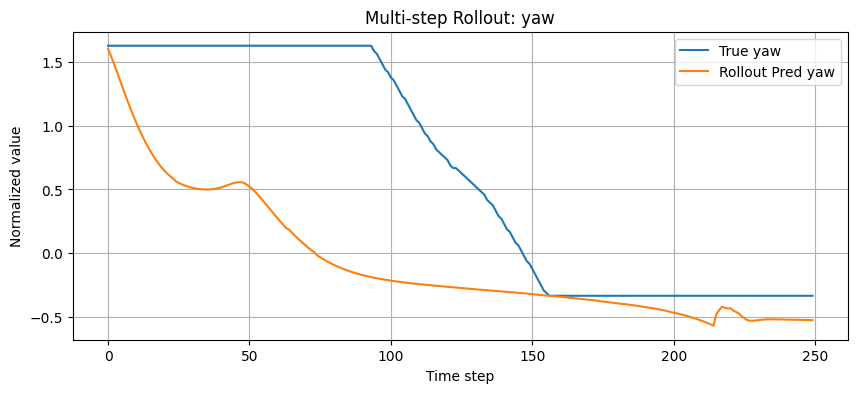

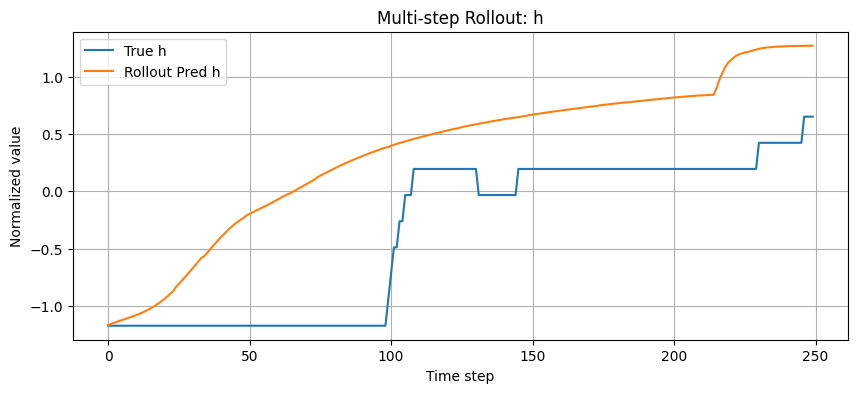

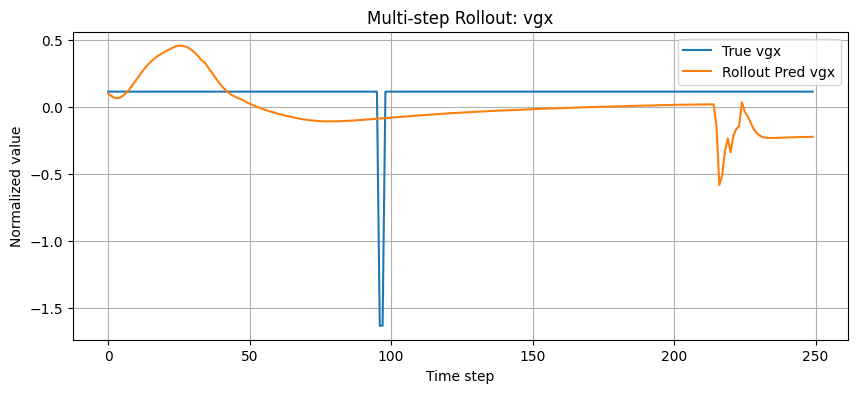

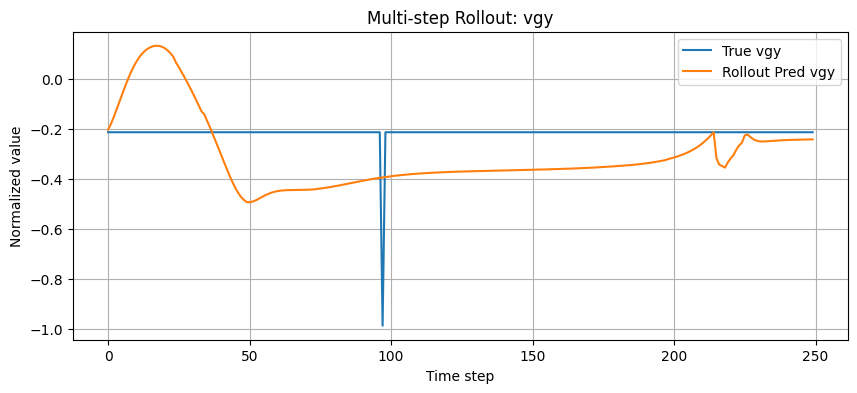

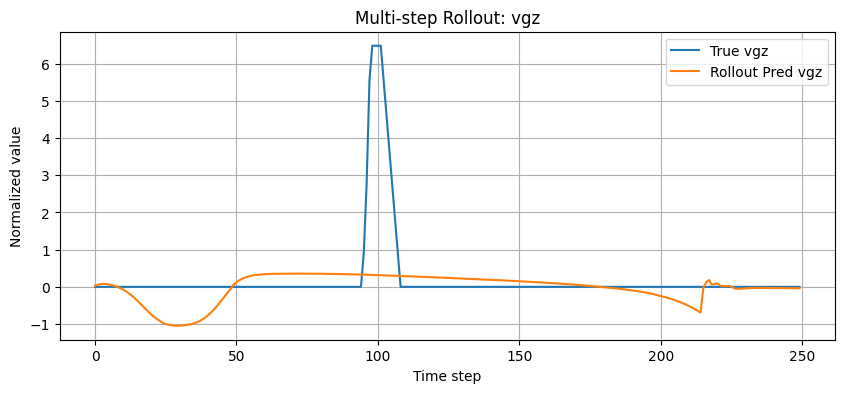

In [ ]:
state_names = ["yaw", "h", "vgx", "vgy", "vgz"]

for i, name in enumerate(state_names):
    plt.figure(figsize=(10,4))
    plt.plot(true_seq[:, i], label=f"True {name}")
    plt.plot(pred_seq[:, i], label=f"Rollout Pred {name}")
    plt.title(f"Multi-step Rollout: {name}")
    plt.xlabel("Time step")
    plt.ylabel("Normalized value")
    plt.legend()
    plt.grid(True)
    plt.show()

In [ ]:
torch.save(model.state_dict(), "tello_neural_ode_stage1.pth")

print("Model saved.")

Model saved.


In [ ]:
import numpy as np

np.save("train_losses.npy", np.array(train_losses))
np.save("test_losses.npy", np.array(test_losses))

print("Losses saved.")

Losses saved.


## Rollout-trained Controlled Neural ODE

In [ ]:
ROLL_STEPS = 10

X_seq = []
U_seq = []
DT_seq = []
Y_seq = []

for i in range(len(train_data["x"]) - ROLL_STEPS):

    x0 = train_data["x"][i]

    u_seq = []
    dt_seq = []
    y_seq = []

    for k in range(ROLL_STEPS):
        u_seq.append(train_data["u"][i + k])
        dt_seq.append(train_data["dt"][i + k])
        y_seq.append(train_data["y"][i + k])

    X_seq.append(x0)
    U_seq.append(u_seq)
    DT_seq.append(dt_seq)
    Y_seq.append(y_seq)

X_seq = np.array(X_seq)
U_seq = np.array(U_seq)
DT_seq = np.array(DT_seq)
Y_seq = np.array(Y_seq)

print(X_seq.shape)
print(U_seq.shape)
print(DT_seq.shape)
print(Y_seq.shape)

(2553, 5)
(2553, 10, 4)
(2553, 10)
(2553, 10, 5)


In [ ]:
X_seq_t = torch.tensor(X_seq, dtype=torch.float32).to(device)
U_seq_t = torch.tensor(U_seq, dtype=torch.float32).to(device)
DT_seq_t = torch.tensor(DT_seq, dtype=torch.float32).unsqueeze(-1).to(device)
Y_seq_t = torch.tensor(Y_seq, dtype=torch.float32).to(device)

print(X_seq_t.shape)
print(U_seq_t.shape)
print(DT_seq_t.shape)
print(Y_seq_t.shape)

torch.Size([2553, 5])
torch.Size([2553, 10, 4])
torch.Size([2553, 10, 1])
torch.Size([2553, 10, 5])


In [ ]:
model_roll = ControlledNeuralODE(
    state_dim=5,
    control_dim=4,
    hidden_dim=128
).to(device)

optimizer = optim.AdamW(
    model_roll.parameters(),
    lr=1e-3,
    weight_decay=1e-4
)

loss_fn = nn.MSELoss()

epochs = 250

roll_train_losses = []

for epoch in range(epochs):

    model_roll.train()

    optimizer.zero_grad()

    x = X_seq_t.clone()

    total_loss = 0.0

    for k in range(ROLL_STEPS):

        u = U_seq_t[:, k]
        dt = DT_seq_t[:, k]

        x = model_roll(x, u, dt)

        y_true = Y_seq_t[:, k]

        step_loss = loss_fn(x, y_true)

        total_loss += step_loss

    total_loss = total_loss / ROLL_STEPS

    total_loss.backward()

    torch.nn.utils.clip_grad_norm_(
        model_roll.parameters(),
        1.0
    )

    optimizer.step()

    roll_train_losses.append(total_loss.item())

    if epoch % 20 == 0:
        print(
            f"Epoch {epoch:03d} | "
            f"Rollout Loss: {total_loss.item():.6f}"
        )

Epoch 000 | Rollout Loss: 0.604955
Epoch 020 | Rollout Loss: 0.388495
Epoch 040 | Rollout Loss: 0.361637
Epoch 060 | Rollout Loss: 0.339234
Epoch 080 | Rollout Loss: 0.320271
Epoch 100 | Rollout Loss: 0.303834
Epoch 120 | Rollout Loss: 0.287626
Epoch 140 | Rollout Loss: 0.273460
Epoch 160 | Rollout Loss: 0.260811
Epoch 180 | Rollout Loss: 0.248330
Epoch 200 | Rollout Loss: 0.235449
Epoch 220 | Rollout Loss: 0.232902
Epoch 240 | Rollout Loss: 0.216984


In [ ]:
model_roll.eval()

T = 250
x0 = x_test[0:1]
u_seq = u_test[:T]
dt_seq = dt_test[:T]
true_seq = y_test[:T].cpu().numpy()

pred_seq_roll = rollout_model(model_roll, x0, u_seq, dt_seq)

print("Rollout prediction:", pred_seq_roll.shape)
print("True sequence:", true_seq.shape)

Rollout prediction: (250, 5)
True sequence: (250, 5)


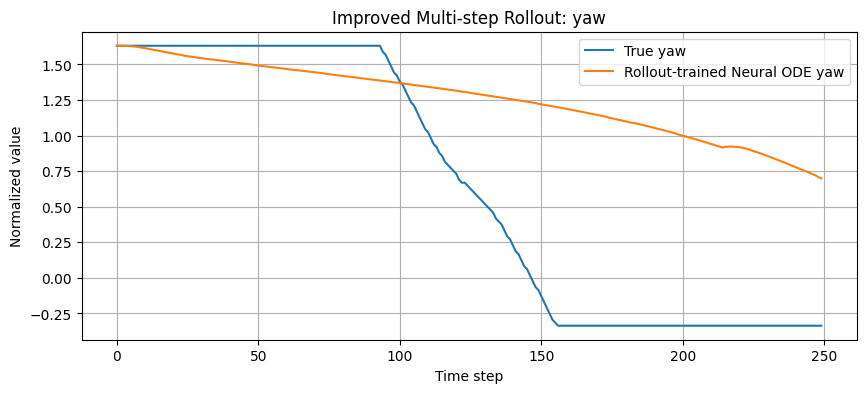

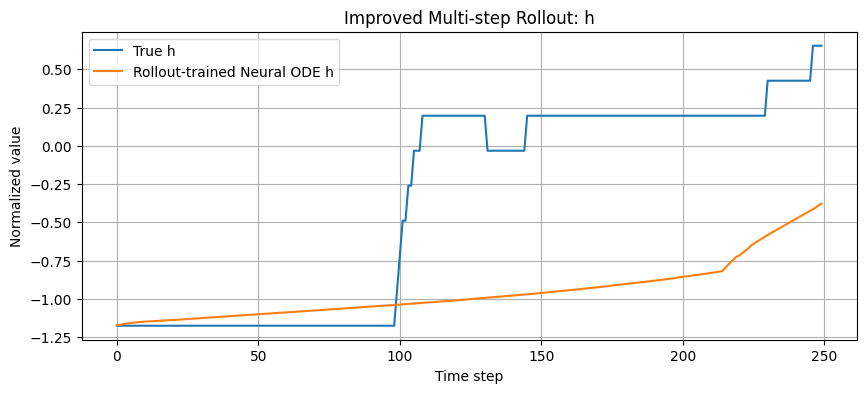

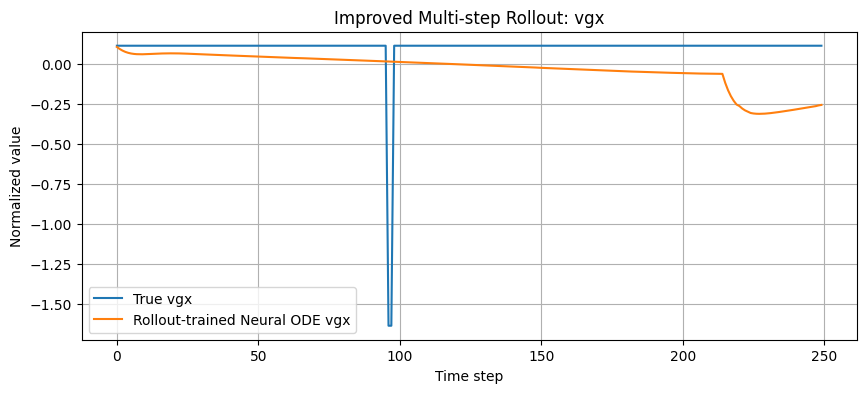

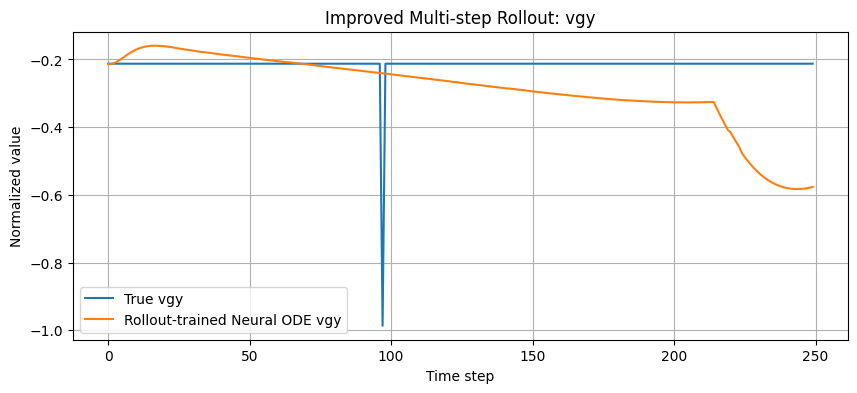

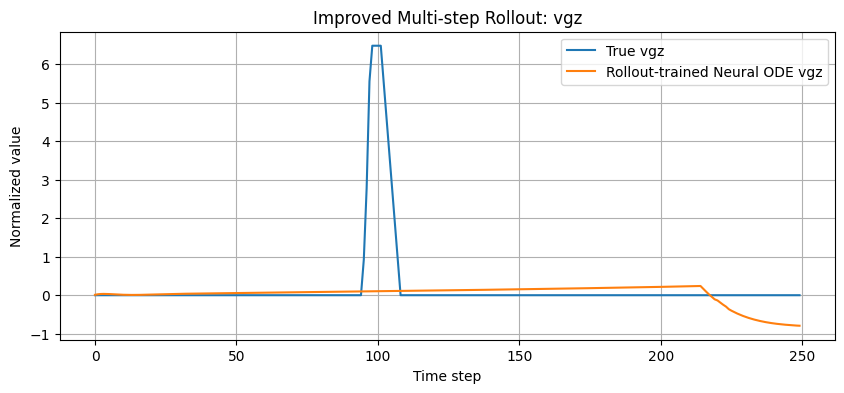

In [ ]:
state_names = ["yaw", "h", "vgx", "vgy", "vgz"]

for i, name in enumerate(state_names):
    plt.figure(figsize=(10,4))
    plt.plot(true_seq[:, i], label=f"True {name}")
    plt.plot(pred_seq_roll[:, i], label=f"Rollout-trained Neural ODE {name}")
    plt.title(f"Improved Multi-step Rollout: {name}")
    plt.xlabel("Time step")
    plt.ylabel("Normalized value")
    plt.legend()
    plt.grid(True)
    plt.show()

In [ ]:
torch.save(model.state_dict(), "neural_ode_onestep.pth")
torch.save(model_roll.state_dict(), "neural_ode_rollout.pth")

In [ ]:
from sklearn.metrics import mean_squared_error, mean_absolute_error
import pandas as pd

state_names = ["yaw", "h", "vgx", "vgy", "vgz"]

results = []

# ---------- One-step model ----------
with torch.no_grad():
    pred_test_onestep = model(x_test, u_test, dt_test)

pred1 = pred_test_onestep.cpu().numpy()
true1 = y_test.cpu().numpy()

# ---------- Rollout-trained model ----------
with torch.no_grad():
    pred_test_roll = model_roll(x_test, u_test, dt_test)

pred2 = pred_test_roll.cpu().numpy()

# ---------- Baseline ----------
baseline = x_test.cpu().numpy()

for i, name in enumerate(state_names):

    # baseline
    rmse_base = np.sqrt(mean_squared_error(true1[:, i], baseline[:, i]))
    mae_base = mean_absolute_error(true1[:, i], baseline[:, i])

    # one-step
    rmse_1 = np.sqrt(mean_squared_error(true1[:, i], pred1[:, i]))
    mae_1 = mean_absolute_error(true1[:, i], pred1[:, i])

    # rollout-trained
    rmse_2 = np.sqrt(mean_squared_error(true1[:, i], pred2[:, i]))
    mae_2 = mean_absolute_error(true1[:, i], pred2[:, i])

    results.append([
        name,
        rmse_base,
        rmse_1,
        rmse_2,
        mae_base,
        mae_1,
        mae_2
    ])

metrics_df = pd.DataFrame(results, columns=[
    "State",
    "Baseline RMSE",
    "OneStep RMSE",
    "Rollout RMSE",
    "Baseline MAE",
    "OneStep MAE",
    "Rollout MAE"
])

metrics_df

,State,Baseline RMSE,OneStep RMSE,Rollout RMSE,Baseline MAE,OneStep MAE,Rollout MAE
0,yaw,0.016132,0.047544,0.037340,0.007606,0.035344,0.023885
1,h,0.045145,0.052129,0.040619,0.008916,0.025380,0.017076
2,vgx,0.402179,0.420947,0.393047,0.076280,0.195657,0.128247
3,vgy,0.140115,0.146404,0.160347,0.025361,0.062903,0.064923
4,vgz,0.442958,0.457070,0.468054,0.053392,0.156758,0.137263


In [ ]:
rollout_results = []

for i, name in enumerate(state_names):

    rmse_rollout = np.sqrt(
        mean_squared_error(
            true_seq[:, i],
            pred_seq[:, i]
        )
    )

    rmse_rollout_trained = np.sqrt(
        mean_squared_error(
            true_seq[:, i],
            pred_seq_roll[:, i]
        )
    )

    rollout_results.append([
        name,
        rmse_rollout,
        rmse_rollout_trained
    ])

rollout_df = pd.DataFrame(
    rollout_results,
    columns=[
        "State",
        "OneStep Rollout RMSE",
        "RolloutTrained Rollout RMSE"
    ]
)

rollout_df

,State,OneStep Rollout RMSE,RolloutTrained Rollout RMSE
0,yaw,0.936627,0.911951
1,h,0.799102,0.815070
2,vgx,0.244579,0.233552
3,vgy,0.176651,0.140408
4,vgz,1.068046,1.075284


In [ ]:
torch.save(model.state_dict(), "neural_ode_onestep.pth")
torch.save(model_roll.state_dict(), "neural_ode_rollout.pth")

metrics_df.to_csv("metrics_summary.csv", index=False)
rollout_df.to_csv("rollout_metrics.csv", index=False)

print("Everything saved.")

Everything saved.


In [ ]:
torch.save(model.state_dict(), "neural_ode_onestep.pth")
torch.save(model_roll.state_dict(), "neural_ode_rollout.pth")

## Summary of Part 6: Rollout-Trained Neural ODE

This part trains a second Controlled Neural ODE using short multi-step sequences instead of only one-step pairs. The training objective minimizes the average prediction error over a rollout window of 10 steps.

This approach is important because it makes the model learn to remain stable over several future predictions. In other words, the model is trained in a way that is closer to how it will be used as a simulator.

The rollout training loss decreases significantly during training, showing that the model learns to reduce multi-step prediction error. The improved rollout plots show better behavior for some state variables, although not all variables improve equally.

The final quantitative metrics confirm this mixed result. The rollout-trained model improves some states such as yaw, height, and forward velocity in one-step metrics, and it improves some long-term rollout errors such as yaw, vgx, and vgy. However, vertical velocity and height remain difficult to predict accurately.

Overall, this section shows that rollout training is useful for improving the digital twin behavior, but the model still needs more diverse training data and better validation.


## Final Conclusion

This notebook presents a data-driven digital twin prototype for a DJI Tello drone. The project starts with a simple Gazebo/synthetic simulation baseline, then moves toward real Tello telemetry and Neural ODE-based learning.

The main contribution is a Controlled Neural ODE model that learns drone dynamics from real flight data. The model uses the current drone state, control command, and time step to predict the next state. The final version includes data cleaning, normalization, supervised learning pair construction, baseline comparison, one-step prediction, multi-step rollout evaluation, and rollout-based training.

The results show that the Neural ODE can learn part of the drone behavior, especially for yaw, height, and some velocity components. However, the model does not outperform the persistence baseline for every variable, and long-term rollout prediction remains challenging due to error accumulation.


